In [1]:
import sys, os, warnings
import numpy as np
import scipy as sp
import pandas as pd
from src.timescales import Timescales
from collections import defaultdict

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

sys.path.extend([r'/home/lindenmp/research_projects/snaplab_tools'])

from src.plotting import create_sydnor_sa_colormap, plot_repeated_measures_violins, plot_subject_level_violins, plot_correlation, plot_brain_surface_data, plot_hierarchy_correlation
from src.data import load_supporting_data
from src.timescales import filter_data_dict, create_ints_dataframe_custom_grouping, convert_data_dict, average_data_dict_converted, compute_deflections

from snaplab_tools.utils import winsorize

warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
def function_helper(data_dict_centiles):
    df_plot = pd.DataFrame()
    for c, condition in enumerate(data_dict_centiles.keys()):
        print(condition)
        df_tmp_1 = pd.DataFrame()
        n_subs_tmp = data_dict_centiles[condition].shape[0]
        for i in np.arange(n_subs_tmp):
            df_tmp_2 = pd.DataFrame()
            df_tmp_2['subject'] = np.zeros(10) + i
            df_tmp_2[condition] = data_dict_centiles[condition][i, :]
            df_tmp_1 = pd.concat((df_tmp_1, df_tmp_2), axis=0)
        if c == 0:
            df_plot['subject'] = df_tmp_1['subject']
        df_plot[condition] = df_tmp_1[condition]
        
    return df_plot

def simple_stat_plot(df_ints, df_centiles, ax, stat='std'):
    df_plot = pd.DataFrame(columns=df_centiles.columns)
    for subj in df_centiles['subject'].unique():
        df_plot.loc[subj, :] = df_centiles.loc[df_centiles['subject'] == subj, :].mean()
    df_plot.drop(labels=['subject',], inplace=True, axis=1)
    if stat == 'std':
        x = df_ints.std()
        y = df_plot[df_ints.columns].std()
        label = 'Stand. Dev.'
    elif stat == 'var':
        x = df_ints.var()
        y = df_plot[df_ints.columns].var()
        label = 'Variance'
    elif stat == 'range':
        x = df_ints.max() - df_ints.min()
        y = df_plot[df_ints.columns].max() - df_plot[df_ints.columns].min()
        label = 'Range'

    ax.plot(x, linewidth=1, marker='.', linestyle='dashed', markersize=4, color="#66c2a5", label='Region')
    ax.plot(y, linewidth=1, marker='.', linestyle='dashed', markersize=4, color="#fc8d62", label='Subject')
    # ax.legend()
    ax.set_ylabel(label)

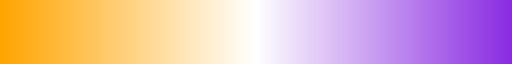

In [3]:
sydnor_sa_cmap = create_sydnor_sa_colormap()
sydnor_sa_cmap

In [4]:
dataset = 'HCP-YA'
# dataset = 'WAND'
# dataset = 'HCP-D'
# dataset = 'PNC'
# dataset = 'Penn_LEAD'
# dataset = 'UCLA'
# dataset = 'NKI'
timescales_processor = Timescales(dataset=dataset, timeseries_data=None)
which_modality = 'FMRI'
# which_modality = 'MEG'

use_resids = True
# use_resids = False
if dataset == 'WAND' or which_modality == 'MEG':
    use_resids = False
    
if which_modality == 'MEG':
    sort_by_median = False
else:
    sort_by_median = True

output_dir = timescales_processor.output_dir
results_dir = os.path.join(output_dir, 'results', dataset)
if not os.path.exists(results_dir):
    os.makedirs(results_dir)
    
supporting_data = load_supporting_data(os.path.join(output_dir, 'data', 'supporting_data'))

Initialized DataLoader for dataset: HCP-YA
Base directory: /mnt/storage_ssd_raid/research_data/HCP_YA
Raw data directory: /mnt/synology/work/research_data/HCP_YA/HCP_1200/
Derivatives data directory: /mnt/storage_ssd_raid/research_data/HCP_YA/derivatives
Output directory: /home/lindenmp/research_projects/intrinsic_neural_timescales
Loaded behavioral data: 1206 subjects

	Initialized Timescales for dataset: HCP-YA
	Output directory: /home/lindenmp/research_projects/intrinsic_neural_timescales


In [5]:
sa_axis = supporting_data['sa_axis']
sf_axis = supporting_data['sf_axis']
yeo_systems = supporting_data['yeo_systems']

In [6]:
if dataset == 'HCP-YA' and which_modality == 'FMRI':
    timescales_processor.load_scan_registry(f'scan_registry_{dataset}_7T.csv')
elif dataset == 'HCP-YA' and which_modality == 'MEG':
    timescales_processor.load_scan_registry(f'scan_registry_{dataset}_MEG.csv')
else:
    timescales_processor.load_scan_registry(f'scan_registry_{dataset}.csv')
timescales_processor.scan_registry.head()

,scan_string,sub,task,space,seg,ses,modality,tr,condition
0,sub-100610_task-rfMRIREST1LR_space-fsLR_seg-Sc...,100610,rfMRIREST1LR,fsLR,Schaefer4007,1,MRI3T,0.72,rest
1,sub-100610_task-rfMRIREST1RL_space-fsLR_seg-Sc...,100610,rfMRIREST1RL,fsLR,Schaefer4007,1,MRI3T,0.72,rest
2,sub-100610_task-rfMRIREST2LR_space-fsLR_seg-Sc...,100610,rfMRIREST2LR,fsLR,Schaefer4007,1,MRI3T,0.72,rest
3,sub-100610_task-rfMRIREST2RL_space-fsLR_seg-Sc...,100610,rfMRIREST2RL,fsLR,Schaefer4007,1,MRI3T,0.72,rest
4,sub-100610_task-tfMRIWMLR_space-fsLR_seg-Schae...,100610,tfMRIWMLR,fsLR,Schaefer4007,1,MRI3T,0.72,task


In [7]:
if dataset == 'HCP-YA':
    timescales_processor.match_registry_to_behavior()
    timescales_processor.df_behavior_matched.shape

In [8]:
subject_ids = timescales_processor.scan_registry['sub'].unique()
n_subs = len(subject_ids)
# np.savetxt(os.path.join(timescales_processor.base_dir, 'subject_ids_7t.txt'), subject_ids, fmt='%d')
print(n_subs)

163


In [9]:
print(use_resids)

if which_modality == 'FMRI':
    output_type = 'timescale_zero_crossing'
    # output_type = 'timescale_zero_crossing_0bk'
    # output_type = 'timescale_zero_crossing_2bk'
    output_type_resid = output_type + '_resids'
elif which_modality == 'MEG':
    # meg_freq = '_lp-30hz'
    # meg_freq = '_lp-10hz'
    # meg_freq = '_lp-5hz'
    # meg_freq = '_lp-1hz'
    meg_freq = '_lp-0.5hz'
    output_type = 'timescale_zero_crossing' + meg_freq
    output_type_resid = output_type + '_resids'
print(output_type)

timescales_processor.get_precomputed_outputs(output_type=output_type)
data_dict = timescales_processor.data_dict.copy()
print(len(data_dict))

if use_resids:
    timescales_processor.get_precomputed_outputs(output_type=output_type_resid)
    data_dict_residuals = timescales_processor.data_dict.copy()
    data_dict, data_dict_residuals = filter_data_dict(data_dict, data_dict_residuals)
else:
    data_dict = filter_data_dict(data_dict, remove_subject_level=True)
print(len(data_dict))

True
timescale_zero_crossing


Loading timescale_zero_crossing: 100%|██████████| 4238/4238 [00:00<00:00, 9127.11it/s]


4238


Loading timescale_zero_crossing_resids: 100%|██████████| 4238/4238 [00:00<00:00, 9373.96it/s]

4238


In [10]:
if which_modality == 'FMRI' and 'HCP' in dataset:
    df_ints = create_ints_dataframe_custom_grouping(data_dict, sort_by_median=sort_by_median, average_all_rest=True, average_7t_movies=True, average_3t_tasks=True)
    # df_ints = create_ints_dataframe_custom_grouping(data_dict, sort_by_median=sort_by_median,
    #                                                 average_7t_rest=True, average_3t_rest=True,
    #                                                 average_3t_task_pairs=True, average_7t_movies=True)
elif which_modality == 'MEG' and 'HCP' in dataset:
    df_ints = create_ints_dataframe_custom_grouping(data_dict, sort_by_median=sort_by_median,
                                                    average_meg_rest=True, average_meg_task=True)
else:
    df_ints = create_ints_dataframe_custom_grouping(data_dict, sort_by_median=sort_by_median)

# if dataset == 'HCP-YA':
    # df_ints = df_ints[['task-REST7T', 'task-REST3T', 'task-MOVIE', 'task-tfMRIWM']]
    
data_dict_centiles = convert_data_dict(data_dict, timescales_processor.scan_registry, brain_map=sa_axis)
if which_modality == 'FMRI' and 'HCP' in dataset:
    data_dict_centiles = average_data_dict_converted(data_dict_centiles, average_3t_tasks=True, average_7t_movies=True, average_all_rest=True)
elif which_modality == 'MEG' and 'HCP' in dataset:
    data_dict_centiles = average_data_dict_converted(data_dict_centiles,
                                                     average_meg_rest=True, average_meg_task=True)

Scan: task-rfMRIREST1LR
  Number of subjects: 163
  Mean INT range: [2.721, 13.640]
Scan: task-rfMRIREST1RL
  Number of subjects: 163
  Mean INT range: [2.823, 14.789]
Scan: task-rfMRIREST2LR
  Number of subjects: 163
  Mean INT range: [3.039, 15.942]
Scan: task-rfMRIREST2RL
  Number of subjects: 163
  Mean INT range: [3.154, 14.413]
Scan: task-tfMRIWMLR
  Number of subjects: 163
  Mean INT range: [1.864, 5.844]
Scan: task-tfMRIWMRL
  Number of subjects: 163
  Mean INT range: [1.855, 5.627]
Scan: task-tfMRIEMOTIONLR
  Number of subjects: 163
  Mean INT range: [2.200, 7.125]
Scan: task-tfMRIEMOTIONRL
  Number of subjects: 163
  Mean INT range: [2.120, 7.394]
Scan: task-tfMRIGAMBLINGLR
  Number of subjects: 163
  Mean INT range: [2.182, 7.363]
Scan: task-tfMRIGAMBLINGRL
  Number of subjects: 163
  Mean INT range: [2.288, 7.399]
Scan: task-tfMRILANGUAGELR
  Number of subjects: 163
  Mean INT range: [2.823, 10.341]
Scan: task-tfMRILANGUAGERL
  Number of subjects: 163
  Mean INT range: [2.6

### Plot: timescales brain plot (average)

[fetch_atlas_schaefer_2018] Dataset found in /home/lindenmp/nilearn_data/schaefer_2018

/home/lindenmp/anaconda3/envs/intrinsic_neural_timescales/lib/python3.11/site-packages/src/plotting.py:1397: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.0, h_pad=-0.5, w_pad=-0.5)


[fetch_atlas_schaefer_2018] Dataset found in /home/lindenmp/nilearn_data/schaefer_2018

/home/lindenmp/anaconda3/envs/intrinsic_neural_timescales/lib/python3.11/site-packages/src/plotting.py:1397: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.0, h_pad=-0.5, w_pad=-0.5)


[fetch_atlas_schaefer_2018] Dataset found in /home/lindenmp/nilearn_data/schaefer_2018

/home/lindenmp/anaconda3/envs/intrinsic_neural_timescales/lib/python3.11/site-packages/src/plotting.py:1397: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.0, h_pad=-0.5, w_pad=-0.5)


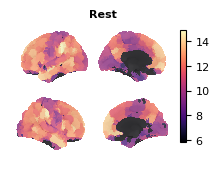

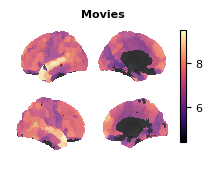

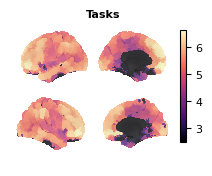

In [11]:
if dataset == 'HCP-YA':
    for column in df_ints.columns:
        fig, axes = plot_brain_surface_data(
            data_vector=df_ints[column],
            parcellation='schaefer_400',
            cmap='magma',
            symmetric_cbar=False,
            title=column, figsize=(2.1, 1.6), font_size=8, cbar_label=None
        )
        fig.savefig(os.path.join(results_dir, f'timescales_brain_{column}.png'), bbox_inches='tight', dpi=300, transparent=True)

### Plot: timescales, average (regional) & subject-level (SA centiles)

Data shape: (400, 3)
Conditions: ['Rest', 'Movies', 'Tasks']


/tmp/ipykernel_1436426/4231031434.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels([''])


Rest
Tasks
Movies
Number of subjects: 163
Selected regions: [0 1 2 3 4 5 6 7 8 9]
Conditions: ['Rest', 'Tasks', 'Movies']
Filtered data shape: (1630, 5)
Expected rows: 1630
Sorted conditions by median (descending):
  Rest: median = 11.2186
  Movies: median = 7.1562
  Tasks: median = 5.1165
Fitting polynomial trends to distribution means...
  Rest: Best fit = Quadratic (R² = 0.920)
  Movies: Best fit = Quadratic (R² = 0.769)
  Tasks: Best fit = Quadratic (R² = 0.876)


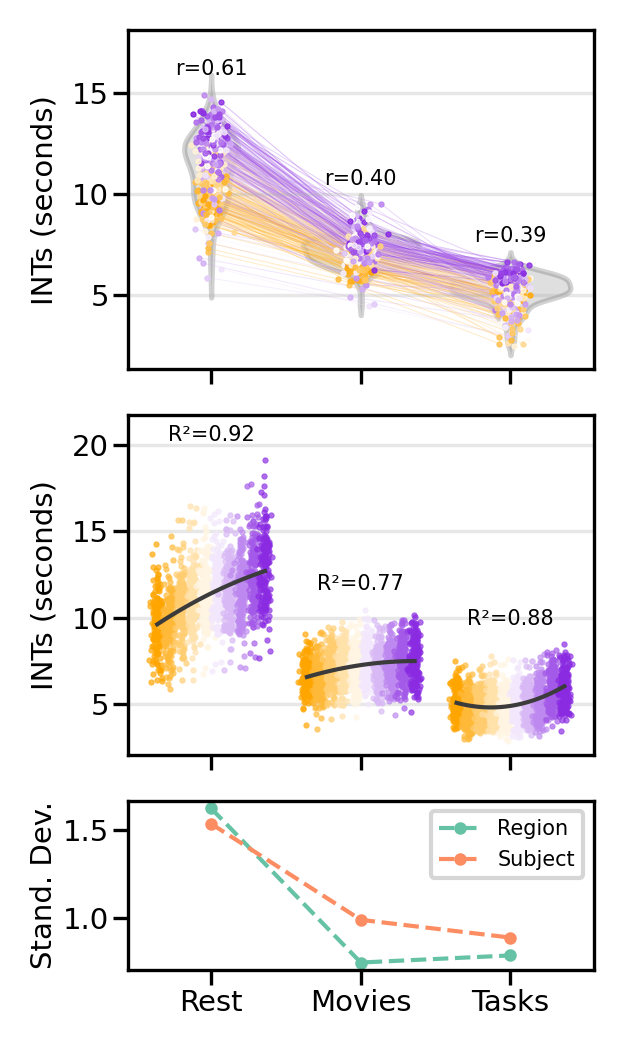

In [12]:
plt.rcParams.update({'font.size': 7})
fig, axes = plt.subplots(nrows=3, ncols=1, sharex=True, sharey=False,
                         figsize=(len(df_ints.columns)*.7, 3.5), 
                         dpi=300, gridspec_kw={'height_ratios':[2, 2, 1]})
axes[0] = plot_repeated_measures_violins(df_ints, axes[0], color_vector=sa_axis, colormap='sydnor_sa', add_colorbar=False,
                                         point_alpha=1, line_alpha=0.3, point_size=0.25, line_width=0.25, violin_alpha=0.25,
                                         correlation_method='pearson')
axes[0].set_xticklabels([''])
axes[0].set_xlabel('')

df_centiles = function_helper(data_dict_centiles)
if dataset == 'WAND':
    df_centiles['reversallearning'] = winsorize(df_centiles['reversallearning'])
axes[1], trend_results = plot_subject_level_violins(df_centiles, axes[1], np.arange(10),
                                                    point_alpha=0.75, point_size=0.25,
                                                    show_violins=False, show_lines=False, fit_trends=True, show_r2_annotation=True,
                                                    hide_legend=True, sort_by_median=sort_by_median)
axes[1].set_xlabel('')

simple_stat_plot(df_ints, df_centiles, axes[2], stat='std')

if dataset == 'HCP-YA':
    axes[0].set_ylabel('INTs (seconds)', fontsize=7)
    axes[1].set_ylabel('INTs (seconds)', fontsize=7)
    axes[2].legend(fontsize=5)
else:
    axes[0].set_ylabel('')
    axes[1].set_ylabel('')
    axes[2].set_ylabel('')

for ax in axes:
    ax.tick_params(axis='y', which='major', pad=1)
    ax.tick_params(axis='x', which='major', pad=1)
    ax.yaxis.set_label_coords(-0.15, 0.5)

plt.tight_layout()
if which_modality == 'MEG':
    file_label = f'timescales_MEG{meg_freq}.png'
else:
    file_label = 'timescales.png'
fig.savefig(os.path.join(results_dir, file_label), bbox_inches='tight', dpi=300, transparent=True)
plt.show()